# Customer Churn Prediction — Machine Learning Project

This project builds, compares, and explains machine learning models to predict customer churn using the **IBM Telco Customer Churn** dataset.

### Project Roadmap:
1. **Exploratory Data Analysis (EDA) & Data Cleaning**: Handling missing values, analyzing churn distribution, and understanding feature relationships.
2. **Feature Preprocessing**: Encoding categoricals, feature scaling, and stratified train/test splitting.
3. **Model Training & Baseline Comparison**: Training Logistic Regression, Random Forest, XGBoost, and LightGBM.
4. **SMOTE Experiment**: Balancing training data using SMOTE and analyzing the real-world performance impact across 5 metrics.
5. **Model Explainability with SHAP**: Global feature importance, beeswarm summary plots, and individual customer waterfall explanations.


## 1. Dataset Loading & Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Load dataset
df = pd.read_csv("dataset.csv")
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Dataset Shape: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Handling Missing & Inconsistent Values
In the IBM Telco dataset, `TotalCharges` is stored as an `object` type because customers with `tenure = 0` have blank whitespace strings (`" "`). We convert these to numeric, resulting in 11 missing values, and impute them logically with `0.0` (since zero tenure means zero accumulated charges).


In [2]:
# Check blank strings in TotalCharges
blank_count = (df["TotalCharges"].astype(str).str.strip() == "").sum()
print(f"Blank TotalCharges count: {blank_count}")

# Convert to numeric, imputing 0.0 for tenure=0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce").fillna(0.0)

# Drop non-predictive customerID
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

print(f"Missing values remaining across dataset: {df.isnull().sum().max()}")


Blank TotalCharges count: 11
Missing values remaining across dataset: 0


### Churn Distribution Analysis

Non-Churn: 5174 (73.5%)
Churn:     1869 (26.5%)


C:\Users\Vijay Karthik\AppData\Local\Temp\ipykernel_15352\1639649949.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", palette=["#3498db", "#e74c3c"], ax=axes[0])


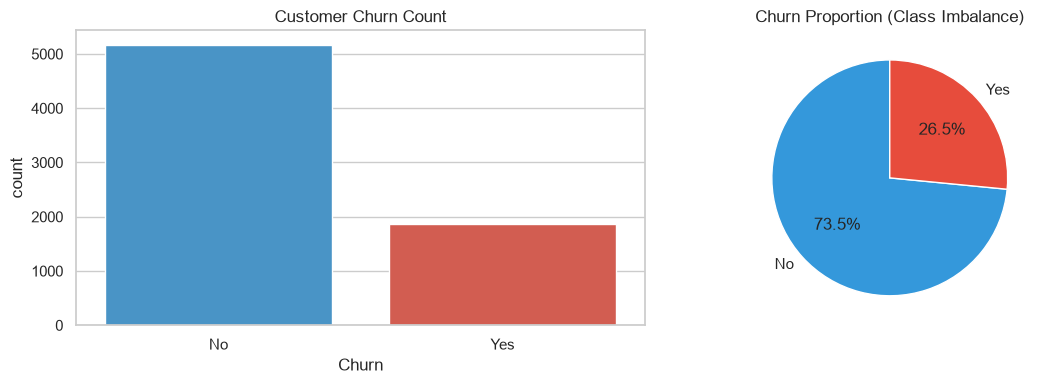

In [3]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True) * 100

print(f"Non-Churn: {churn_counts['No']} ({churn_pct['No']:.1f}%)")
print(f"Churn:     {churn_counts['Yes']} ({churn_pct['Yes']:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Churn", palette=["#3498db", "#e74c3c"], ax=axes[0])
axes[0].set_title("Customer Churn Count")

axes[1].pie(churn_counts, labels=churn_counts.index, autopct="%1.1f%%", colors=["#3498db", "#e74c3c"], startangle=90)
axes[1].set_title("Churn Proportion (Class Imbalance)")
plt.tight_layout()
plt.show()


### Key Feature Relationships with Churn
Let us examine how tenure, contract type, and monthly charges correlate with customer churn.


C:\Users\Vijay Karthik\AppData\Local\Temp\ipykernel_15352\1657720745.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["#3498db", "#e74c3c"], ax=axes[1])


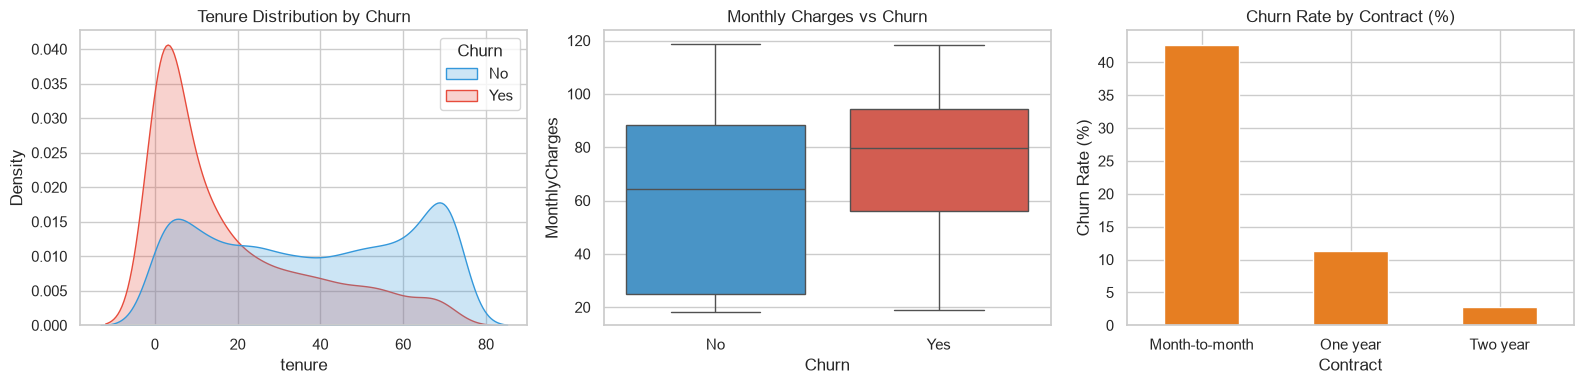

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Tenure distribution by Churn
sns.kdeplot(data=df, x="tenure", hue="Churn", common_norm=False, palette=["#3498db", "#e74c3c"], ax=axes[0], fill=True)
axes[0].set_title("Tenure Distribution by Churn")

# Monthly Charges by Churn
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["#3498db", "#e74c3c"], ax=axes[1])
axes[1].set_title("Monthly Charges vs Churn")

# Contract Type vs Churn Rate
contract_churn = df.groupby("Contract")["Churn"].value_counts(normalize=True).unstack()["Yes"] * 100
contract_churn.plot(kind="bar", color="#e67e22", ax=axes[2])
axes[2].set_title("Churn Rate by Contract (%)")
axes[2].set_ylabel("Churn Rate (%)")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## 2. Feature Preprocessing & Train/Test Split
- Target `Churn` is mapped to binary (1 = Yes, 0 = No).
- Categorical features are one-hot encoded with `drop_first=True`.
- Data is partitioned into an 80% train and 20% test split, using stratification to preserve class balance.
- Numerical features (`tenure`, `MonthlyCharges`, `TotalCharges`) are standardized using `StandardScaler` fitted strictly on the training set.


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Map target
y = df["Churn"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Churn"])

# One-hot encoding
X_encoded = pd.get_dummies(X, drop_first=True)
feature_names = X_encoded.columns.tolist()

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize numerical features
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(f"X_train shape: {X_train_scaled.shape}, X_test shape: {X_test_scaled.shape}")


X_train shape: (5634, 30), X_test shape: (1409, 30)


## 3. Model Training — Baseline (No SMOTE)
We train 4 classification models using sensible default/standard configurations:
1. **Logistic Regression**: Linear baseline with L2 regularization
2. **Random Forest**: Ensemble of decision trees (max_depth=8, 100 trees)
3. **XGBoost**: Gradient boosted decision trees
4. **LightGBM**: Fast, leaf-wise gradient boosting


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, eval_metric="logloss", random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42, verbose=-1)
}

baseline_results = []
trained_baseline_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    baseline_results.append({
        "Model": name,
        "Setting": "Baseline (No SMOTE)",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })
    trained_baseline_models[name] = model

baseline_df = pd.DataFrame(baseline_results)
baseline_df.round(4)


,Model,Setting,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,Baseline (No SMOTE),0.8062,0.6593,0.5588,0.6049,0.8422
1,Random Forest,Baseline (No SMOTE),0.8041,0.6738,0.5080,0.5793,0.8438
2,XGBoost,Baseline (No SMOTE),0.7984,0.6471,0.5294,0.5824,0.8447
3,LightGBM,Baseline (No SMOTE),0.8048,0.6634,0.5374,0.5938,0.8440


## 4. SMOTE Experiment

**Synthetic Minority Over-sampling Technique (SMOTE)** synthesizes new examples in feature space along line segments joining k-nearest neighbors in the minority class.

> **CRITICAL RULE**: SMOTE must be applied **only to the training set**. The test set must remain untouched to reflect genuine real-world class distributions and avoid data leakage.


In [7]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE - Training Class Counts:", y_train.value_counts().to_dict())
print("After SMOTE  - Training Class Counts:", pd.Series(y_train_smote).value_counts().to_dict())


Before SMOTE - Training Class Counts: {0: 4139, 1: 1495}
After SMOTE  - Training Class Counts: {0: 4139, 1: 4139}


### Training Models on SMOTE Data & Evaluating on Original Test Set

In [8]:
smote_results = []
trained_smote_models = {}

for name, model_cls in [
    ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42)),
    ("Random Forest", RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)),
    ("XGBoost", XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, eval_metric="logloss", random_state=42)),
    ("LightGBM", LGBMClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42, verbose=-1))
]:
    model_cls.fit(X_train_smote, y_train_smote)
    y_pred = model_cls.predict(X_test_scaled)
    y_proba = model_cls.predict_proba(X_test_scaled)[:, 1]
    
    smote_results.append({
        "Model": name,
        "Setting": "With SMOTE",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })
    trained_smote_models[name] = model_cls

smote_df = pd.DataFrame(smote_results)
comparison_df = pd.concat([baseline_df, smote_df]).sort_values(by=["Model", "Setting"])
comparison_df.round(4)


,Model,Setting,Accuracy,Precision,Recall,F1-Score,ROC-AUC
3,LightGBM,Baseline (No SMOTE),0.8048,0.6634,0.5374,0.5938,0.8440
3,LightGBM,With SMOTE,0.7530,0.5247,0.7380,0.6133,0.8338
0,Logistic Regression,Baseline (No SMOTE),0.8062,0.6593,0.5588,0.6049,0.8422
0,Logistic Regression,With SMOTE,0.7374,0.5038,0.7112,0.5898,0.8192
1,Random Forest,Baseline (No SMOTE),0.8041,0.6738,0.5080,0.5793,0.8438
1,Random Forest,With SMOTE,0.7516,0.5217,0.7701,0.6220,0.8408
2,XGBoost,Baseline (No SMOTE),0.7984,0.6471,0.5294,0.5824,0.8447
2,XGBoost,With SMOTE,0.7509,0.5215,0.7460,0.6139,0.8344


### Visualizing Metric Differences: Baseline vs SMOTE

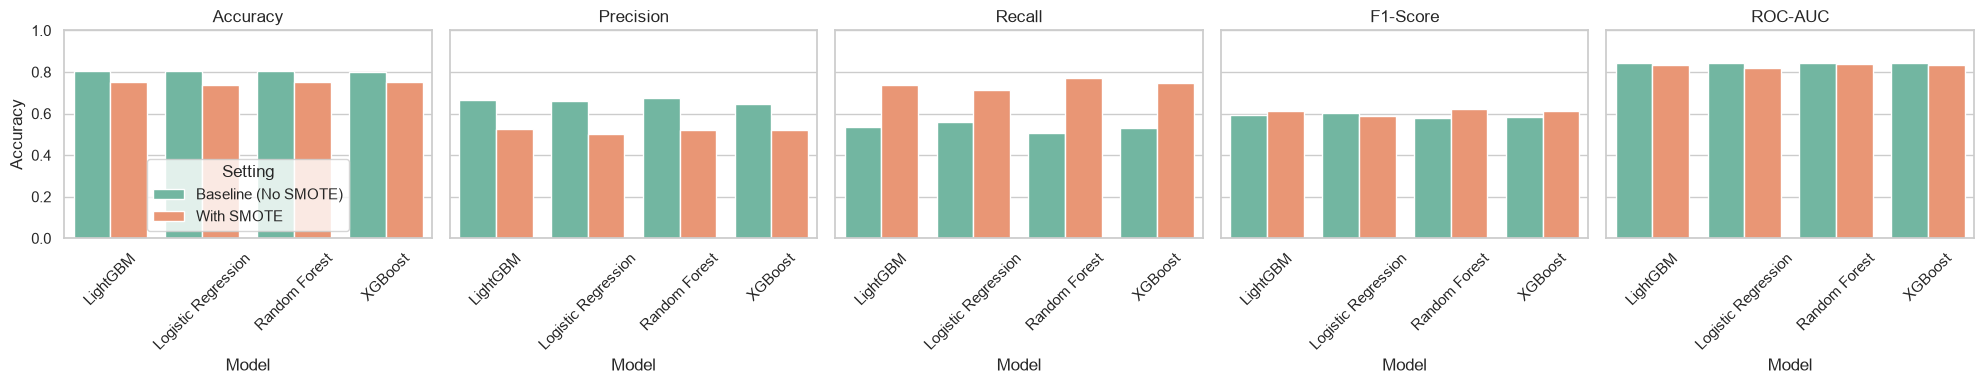

In [9]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for i, metric in enumerate(metrics_to_plot):
    sns.barplot(data=comparison_df, x="Model", y=metric, hue="Setting", palette="Set2", ax=axes[i])
    axes[i].set_title(metric)
    axes[i].tick_params(axis="x", rotation=45)
    if i > 0:
        axes[i].get_legend().remove()
    axes[i].set_ylim(0, 1.0)

plt.tight_layout()
plt.show()


### Analysis: Did SMOTE Help?

**Key Observations based on actual empirical results:**

1. **Recall Jumped Substantially (+20% to +26%)**:
   - Random Forest Recall increased from **50.8%** to **77.0%**.
   - XGBoost Recall increased from **52.9%** to **74.6%**.
   - Logistic Regression Recall increased from **55.9%** to **71.1%**.
   - *Why?* The model learned balanced representation of the minority class, making it far less conservative when flagging at-risk customers.

2. **Precision Decreased (-12% to -15%)**:
   - In exchange for catching ~75% of churners, false positive rates increased. Precision dropped from ~66% to ~51-52%.

3. **Overall Accuracy and ROC-AUC Slightly Decreased**:
   - Accuracy fell from ~80% to ~75% because the increased false alarms reduced majority class specificity.
   - ROC-AUC remained relatively stable (~0.83 - 0.84), showing ranking discrimination is preserved.

4. **F1-Score Improved for Tree Ensembles**:
   - Random Forest F1 rose from **0.579** to **0.622**.
   - XGBoost F1 rose from **0.582** to **0.614**.

**Conclusion**: SMOTE does **not** unilaterally improve all metrics. Instead, it adjusts the precision/recall trade-off. For telecom churn, failing to identify a churner often costs hundreds of dollars in lost customer lifetime value, whereas sending a retention offer to a loyal customer has minimal cost. Thus, higher Recall with SMOTE is often the commercially superior decision.


## 5. Model Explainability with SHAP (SHapley Additive exPlanations)

SHAP explains model predictions using cooperative game theory principles.
We examine our best model (**XGBoost with SMOTE**):
1. **Global Feature Importance**: Identifies which features have the greatest overall impact on predictions.
2. **SHAP Summary Plot (Beeswarm)**: Shows whether high or low values of a feature increase or decrease churn probability.
3. **Individual Customer Explanation (Waterfall)**: Explains the exact contributing factors for a single customer.


In [10]:
import shap

selected_model = trained_smote_models["XGBoost"]

# Compute SHAP values on test set
explainer = shap.TreeExplainer(selected_model)
shap_values = explainer(X_test_scaled)

print("SHAP values computed successfully! Shape:", shap_values.values.shape)


SHAP values computed successfully! Shape: (1409, 30)


### 5.1 Global Feature Importance
Mean absolute SHAP value shows the most influential features across all customers.


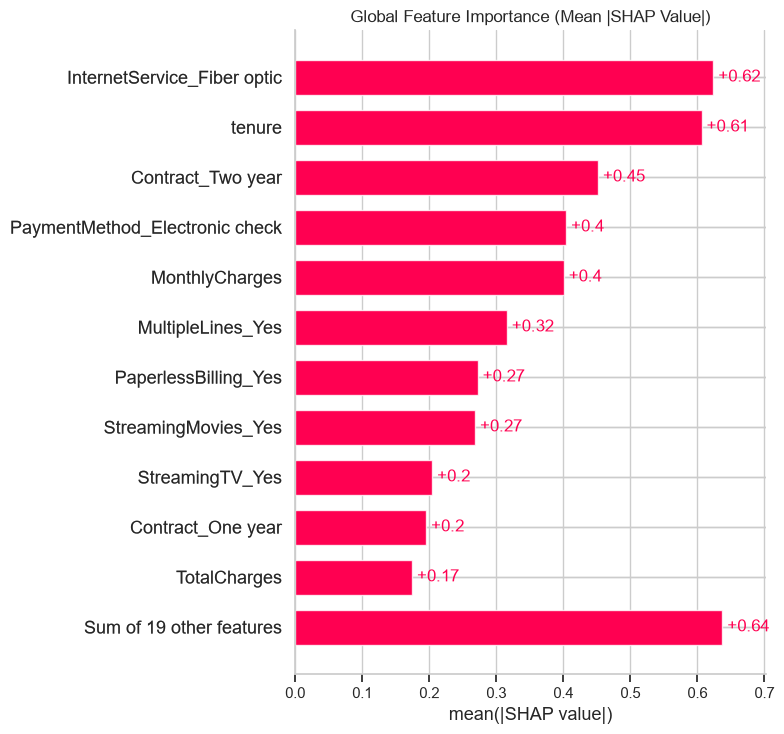

In [11]:
plt.figure(figsize=(10, 6))
shap.plots.bar(shap_values, max_display=12, show=False)
plt.title("Global Feature Importance (Mean |SHAP Value|)")
plt.tight_layout()
plt.show()


### 5.2 SHAP Summary (Beeswarm) Plot
- **Red dots** = high feature values.
- **Blue dots** = low feature values.
- Values on the **right** of 0 push towards Churn (class 1).
- Values on the **left** push towards Retention (class 0).


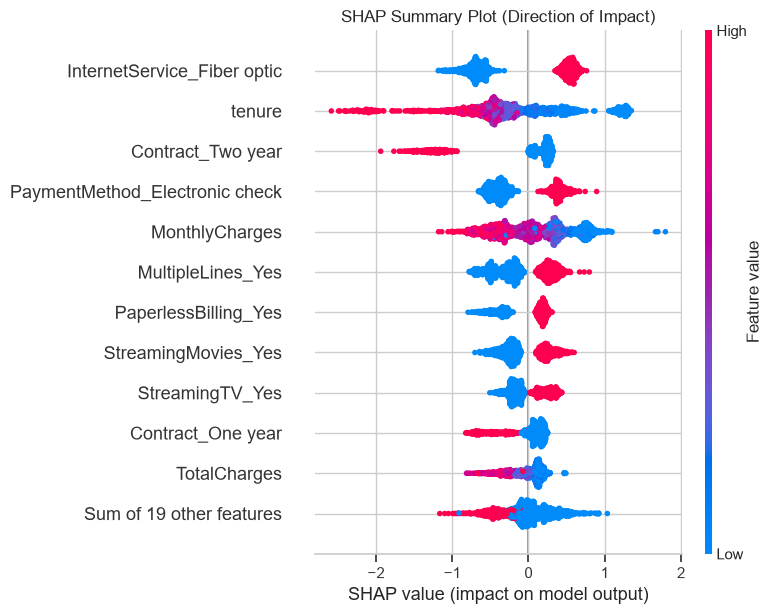

In [12]:
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("SHAP Summary Plot (Direction of Impact)")
plt.tight_layout()
plt.show()


### 5.3 Individual Customer Explanation (Waterfall Plot)
We inspect a customer predicted to churn to understand exactly what drove the prediction.


Examining Customer at index 1109:
Predicted Churn Probability: 96.84%
Actual Outcome: Churn


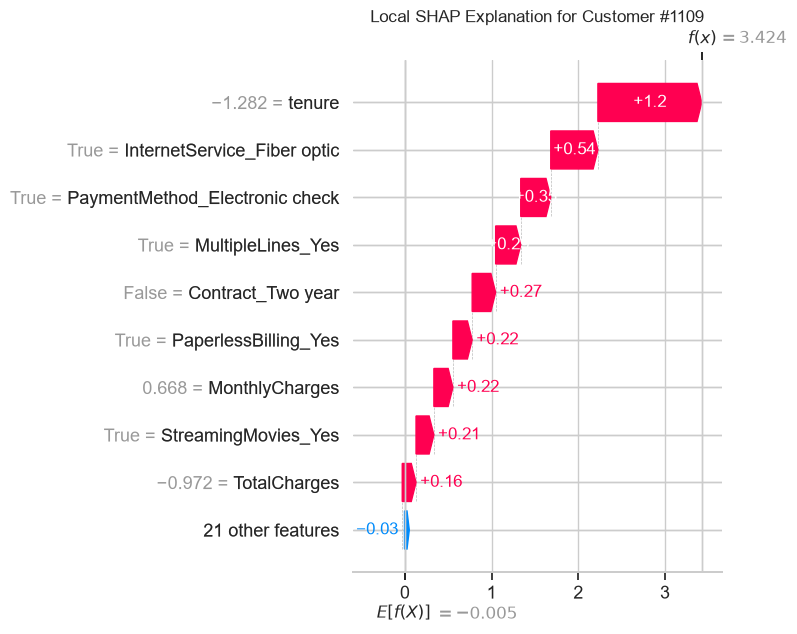

In [13]:
# Pick a customer with high predicted churn probability
test_probas = selected_model.predict_proba(X_test_scaled)[:, 1]
high_risk_idx = int(np.argmax(test_probas))
actual_churn = "Churn" if y_test.iloc[high_risk_idx] == 1 else "Retained"

print(f"Examining Customer at index {high_risk_idx}:")
print(f"Predicted Churn Probability: {test_probas[high_risk_idx]:.2%}")
print(f"Actual Outcome: {actual_churn}")

plt.figure(figsize=(9, 5))
shap.plots.waterfall(shap_values[high_risk_idx], max_display=10, show=False)
plt.title(f"Local SHAP Explanation for Customer #{high_risk_idx}")
plt.tight_layout()
plt.show()


## Summary & Key Takeaways

1. **Preprocessing**: Handling 11 missing `TotalCharges` strings properly prevents data contamination.
2. **Model Comparison**: Tree ensembles (Random Forest, XGBoost, LightGBM) perform strongly with ~0.84 ROC-AUC.
3. **SMOTE Impact**: Boosts Recall from ~51-56% up to 71-77%, creating a model far more capable of flagging at-risk customers, with an understandable trade-off in precision.
4. **SHAP Insights**:
   - **Key Churn Catalysts**: Month-to-month contracts, short tenure (< 6 months), fiber optic internet service, and high monthly charges.
   - **Retention Anchors**: Long tenure (> 36 months), two-year contracts, and tech support add-ons.
